# Actividad :  Resolución de problema mediante búsqueda heurística

Este código ha sido desarrollado a partir de la Autonomous Logistics Route Optimization Engine, contando con apoyo de Google Gemini. Su finalidad es mejorar la visualización del comportamiento de los diferentes algoritmos utilizados en los distintos casos analizados.

## Instalación de librerías y configuración

In [6]:
import sys
import os

# 1. Instalación de librerías en el núcleo actual
print("🔄 Verificando librerías...")
!{sys.executable} -m pip install simpleai flask pydot graphviz matplotlib numpy

# 2. Crear carpeta para guardar las imágenes
CARPETA_SALIDA = "resultados_rutas"
if not os.path.exists(CARPETA_SALIDA):
    os.makedirs(CARPETA_SALIDA)
    print(f"✅ Carpeta '{CARPETA_SALIDA}' creada.")
else:
    print(f"✅ Carpeta '{CARPETA_SALIDA}' ya existe.")

# 3. Importaciones
from __future__ import print_function
import math
import matplotlib.pyplot as plt
import numpy as np
from simpleai.search.viewers import BaseViewer
from simpleai.search import SearchProblem, astar, breadth_first, depth_first, uniform_cost

# Comando para mostrar gráficos en el notebook
%matplotlib inline

🔄 Verificando librerías...
✅ Carpeta 'resultados_rutas' ya existe.


Aquí cargamos las librerías y configuramos Jupyter para que muestre los gráficos.

## Definición del Problema

Aquí definimos la lógica del juego (reglas, movimientos y heurísticas).

In [7]:
class GameWalkPuzzle(SearchProblem):

    def __init__(self, board, costs, heuristic_number=1):
        self.board = board
        self.goal = (0, 0)
        self.costs = costs
        self.heuristic_number = heuristic_number
        self.initial = (0, 0)

        for y in range(len(self.board)):
            for x in range(len(self.board[y])):
                if self.board[y][x].lower() == "t":
                    self.initial = (x, y)
                elif self.board[y][x].lower() == "p":
                    self.goal = (x, y)

        super(GameWalkPuzzle, self).__init__(initial_state=self.initial)

    def actions(self, state):
        actions = []
        for action in list(self.costs.keys()):
            newx, newy = self.result(state, action)
            if 0 <= newy < len(self.board) and 0 <= newx < len(self.board[0]):
                if self.board[newy][newx] != "#":
                    actions.append(action)
        return actions

    def result(self, state, action):
        x, y = state
        if action.count("up"): y -= 1
        if action.count("down"): y += 1
        if action.count("left"): x -= 1
        if action.count("right"): x += 1
        return (x, y)

    def is_goal(self, state):
        return state == self.goal

    def cost(self, state, action, state2):
        return self.costs[action]

    # --- Heurísticas ---
    def heuristic1(self, state): # Manhattan
        x, y = state
        gx, gy = self.goal
        return abs(x - gx) + abs(y - gy)

    def heuristic2(self, state): # Chebyshev
        x, y = state
        gx, gy = self.goal
        return max(abs(x - gx), abs(y - gy))

    def heuristic3(self, state): # Manhattan x2
        x, y = state
        gx, gy = self.goal
        return 2 * (abs(x - gx) + abs(y - gy))

    def heuristic(self, state):
        if self.heuristic_number == 1: return self.heuristic1(state)
        elif self.heuristic_number == 2: return self.heuristic2(state)
        elif self.heuristic_number == 3: return self.heuristic3(state)
        else: raise Exception("La heurística debe ser 1, 2 o 3.")

## Funciones de Visualización Gráfica

Vemos los resultados de una forma más visual con Matplotlib en lugar de solo texto.

In [8]:
def searchInfo(problem, result):
    # Función auxiliar para calcular coste real del camino
    def getTotalCost(problem, result):
        originState = problem.initial_state
        totalCost = 0
        for action, endingState in result.path():
            if action is not None:
                totalCost += problem.cost(originState, action, endingState)
                originState = endingState
        return totalCost

    # Solo devolvemos Pasos y Coste (Limpiamos info técnica)
    return "Pasos: {0} | Coste Total: {1}".format(len(result.path()), getTotalCost(problem, result))

def dibujar_grafica(problem, result, map_data, titulo_grafico, nombre_archivo=None):
    # 1. Preparar datos
    alto, ancho = len(map_data), len(map_data[0])
    grid = np.zeros((alto, ancho))
    
    # 1 = Muro, 0 = Libre
    for y in range(alto):
        for x in range(ancho):
            grid[y][x] = 1 if map_data[y][x] == '#' else 0

    path_coords = [x[1] for x in result.path()]
    if path_coords:
        px, py = zip(*path_coords)
    else:
        px, py = [], []

    # 2. Configurar figura
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.imshow(grid, cmap='Greys', origin='upper')
    
    # Rejilla
    ax.set_xticks(np.arange(-.5, ancho, 1), minor=True)
    ax.set_yticks(np.arange(-.5, alto, 1), minor=True)
    ax.grid(which='minor', color='black', linestyle='-', linewidth=0.5)
    
    # Camino
    ax.plot(px, py, color='blue', linewidth=3, marker='o', markersize=5, label='Camino', alpha=0.7)
    
    # Inicio y Meta
    ix, iy = problem.initial
    gx, gy = problem.goal
    ax.plot(ix, iy, marker='D', color='green', markersize=10, linestyle='None', label='Inicio')
    ax.plot(gx, gy, marker='*', color='red', markersize=15, linestyle='None', label='Meta')
    
    # Títulos
    ax.set_title(titulo_grafico, fontsize=11, fontweight='bold')
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.05), ncol=3)
    ax.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)
    
    # 3. Guardar imagen si se pide
    if nombre_archivo:
        ruta = os.path.join(CARPETA_SALIDA, f"{nombre_archivo}.png")
        plt.savefig(ruta, bbox_inches='tight')
        print(f"   💾 Imagen guardada: {ruta}")

    plt.show()

def resultado_experimento(problem, MAP, result, nombre_algoritmo, nombre_archivo_guardar):
    # Obtenemos info limpia
    info = searchInfo(problem, result)
    print(f"Resultados {nombre_algoritmo}: {info}")
    
    # Dibujamos y guardamos
    titulo = f"{nombre_algoritmo}\n{info}"
    dibujar_grafica(problem, result, MAP, titulo, nombre_archivo_guardar)

## Ejecución de los Casos

Corremos los casos y generamos las gráficas.


CASO 1: Búsqueda Ciega (BFS vs DFS)
Resultados Búsqueda en Amplitud (BFS): Pasos: 6 | Coste Total: 5.0
   💾 Imagen guardada: resultados_rutas/Caso1_Búsqueda_en_Amplitud_BFS.png


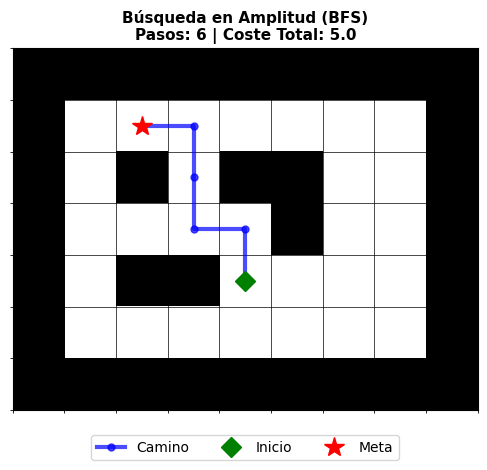

Resultados Búsqueda en Profundidad (DFS): Pasos: 12 | Coste Total: 11.0
   💾 Imagen guardada: resultados_rutas/Caso1_Búsqueda_en_Profundidad_DFS.png


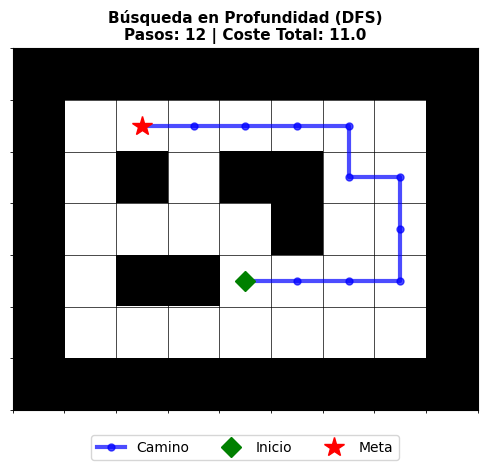


CASO 2: Costes Variables (Terreno difícil)
Resultados Búsqueda en Amplitud (BFS): Pasos: 6 | Coste Total: 9.0
   💾 Imagen guardada: resultados_rutas/Caso2_Búsqueda_en_Amplitud_(BFS).png


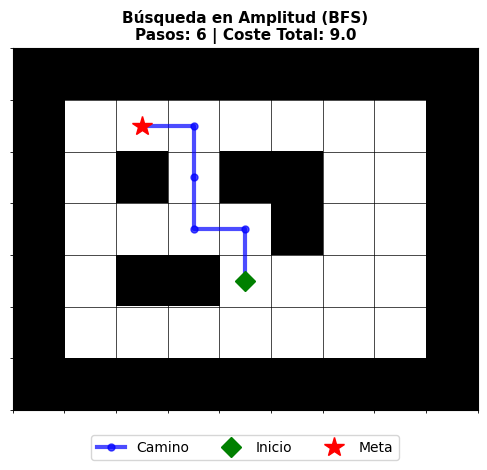

Resultados Dijkstra (Coste Uniforme): Pasos: 6 | Coste Total: 9.0
   💾 Imagen guardada: resultados_rutas/Caso2_Dijkstra_(Coste_Uniforme).png


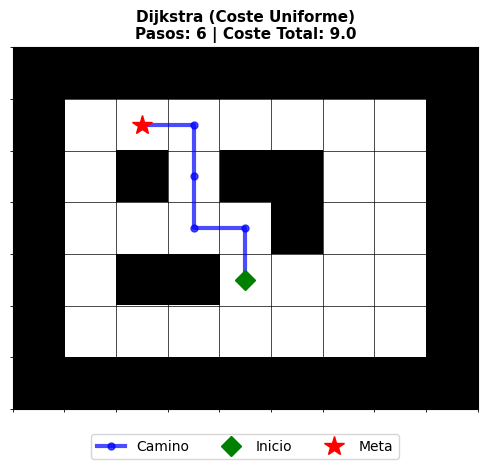

Resultados Algoritmo A*: Pasos: 6 | Coste Total: 9.0
   💾 Imagen guardada: resultados_rutas/Caso2_Algoritmo_A*.png


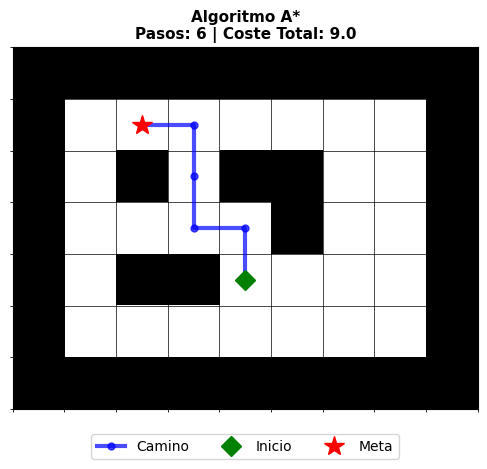


CASO 3: Comparación Heurísticas (Solo A*)
Resultados A* (Heurística 1): Pasos: 6 | Coste Total: 9.0
   💾 Imagen guardada: resultados_rutas/Caso3_AStar_Heuristica_1.png


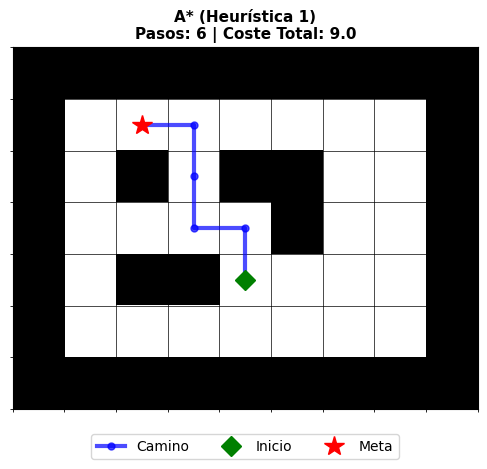

Resultados A* (Heurística 2): Pasos: 6 | Coste Total: 9.0
   💾 Imagen guardada: resultados_rutas/Caso3_AStar_Heuristica_2.png


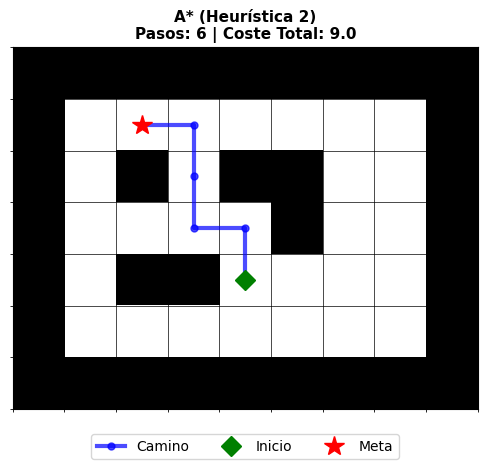

Resultados A* (Heurística 3): Pasos: 6 | Coste Total: 9.0
   💾 Imagen guardada: resultados_rutas/Caso3_AStar_Heuristica_3.png


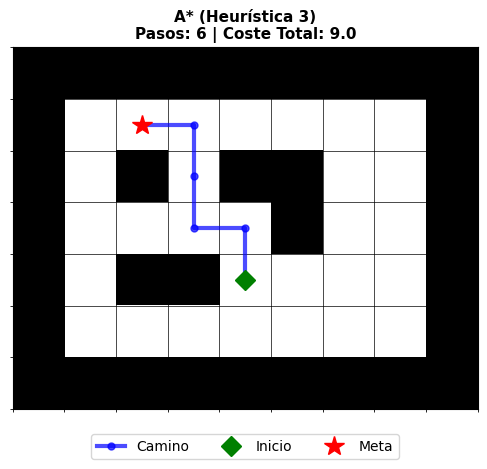

In [9]:
# --- MAPA COMÚN ---
MAP_ASCII = """
#########
# P     #
# # ##  #
#    #  #
# ##T   #
#       #
#########
"""
MAP = [list(x) for x in MAP_ASCII.split("\n") if x]

# Diccionario para traducir nombres
nombres_espanol = {
    breadth_first: "Búsqueda en Amplitud (BFS)",
    depth_first:   "Búsqueda en Profundidad (DFS)",
    uniform_cost:  "Dijkstra (Coste Uniforme)",
    astar:         "Algoritmo A*"
}

# ==========================================
# CASO 1: Búsqueda Ciega
# ==========================================
print("\n" + "="*40 + "\nCASO 1: Búsqueda Ciega (BFS vs DFS)\n" + "="*40)
COSTS_1 = {"up": 1.0, "down": 1.0, "left": 1.0, "right": 1.0}

for alg in [breadth_first, depth_first]:
    problem = GameWalkPuzzle(MAP, COSTS_1)
    result = alg(problem, graph_search=True, viewer=BaseViewer())
    
    nombre = nombres_espanol[alg]
    archivo = f"Caso1_{nombre.replace(' ', '_').replace('(', '').replace(')', '')}"
    resultado_experimento(problem, MAP, result, nombre, archivo)

# ==========================================
# CASO 2: Costes Variables
# ==========================================
print("\n" + "="*40 + "\nCASO 2: Costes Variables (Terreno difícil)\n" + "="*40)
COSTS_2 = {"up": 1.0, "down": 3.0, "left": 3.0, "right": 1.0}

for alg in [breadth_first, uniform_cost, astar]:
    problem = GameWalkPuzzle(MAP, COSTS_2)
    result = alg(problem, graph_search=True, viewer=BaseViewer())
    
    nombre = nombres_espanol[alg]
    archivo = f"Caso2_{nombre.replace(' ', '_')}"
    resultado_experimento(problem, MAP, result, nombre, archivo)

# ==========================================
# CASO 3: Comparación Heurísticas
# ==========================================
print("\n" + "="*40 + "\nCASO 3: Comparación Heurísticas (Solo A*)\n" + "="*40)

for h in [1, 2, 3]:
    problem = GameWalkPuzzle(MAP, COSTS_2, heuristic_number=h)
    result = astar(problem, graph_search=True, viewer=BaseViewer())
    
    nombre = f"A* (Heurística {h})"
    archivo = f"Caso3_AStar_Heuristica_{h}"
    resultado_experimento(problem, MAP, result, nombre, archivo)

## DEMOSTRACIÓN: Impacto de la Estructura del Mapa en la Eficiencia de A*


EJECUTANDO ANÁLISIS DE EFICIENCIA A*


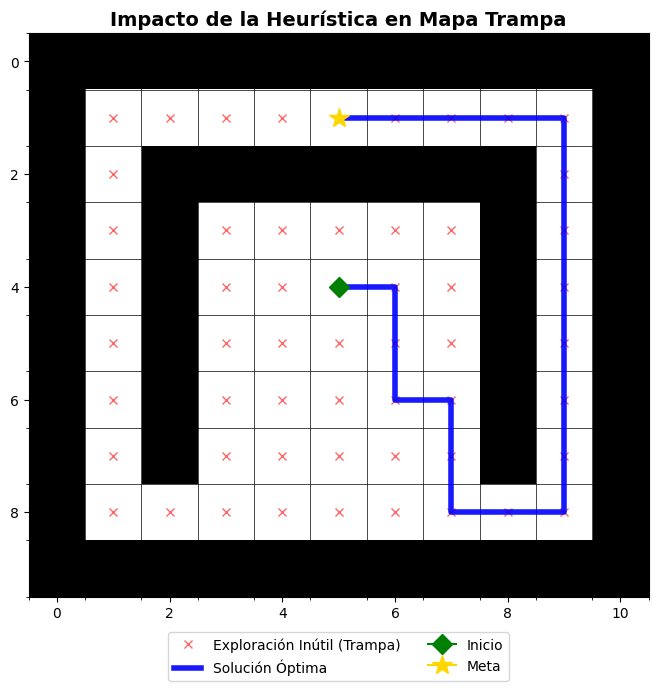


--- REPORTE DE RESULTADOS ---
1. DATOS EMPÍRICOS:
   - Longitud del camino óptimo:  20
   - Nodos totales visitados:     54
   - Nodos explorados inútilmente:34
   - Eficiencia del algoritmo:    37.04% (Baja)

2. JUSTIFICACIÓN TEÓRICA:
   A* decide qué nodo visitar basándose en f(n) = g(n) + h(n).
   - g(n): Coste real desde el inicio.
   - h(n): Distancia estimada a la meta (Manhattan).

   En este mapa, dentro de la 'U', moverse hacia ARRIBA reduce h(n).
   Aunque es un camino sin salida, la matemática le dice al algoritmo:
   'Te estás acercando a la meta', reduciendo f(n).

   Para salir, el algoritmo debe moverse hacia ABAJO, lo que aumenta h(n).
   A* se resiste a aumentar el coste estimado hasta que no tiene otra opción,
   obligándolo a 'pintar de rojo' todo el interior de la trampa primero.

3. CONCLUSIÓN:
   Este experimento demuestra que una heurística admisible garantiza
   encontrar el camino más corto (Optimalidad), pero NO garantiza
   que se visiten pocos nodos (Eficie

In [10]:
# ==========================================
# DEMOSTRACIÓN FINAL: REPORTE TÉCNICO Y VISUALIZACIÓN
# ==========================================

# --- 1. DEFINICIÓN DEL PROBLEMA ---
class GameWalkPuzzle(SearchProblem):
    def __init__(self, board, costs, heuristic_number=1):
        self.board = board
        self.goal = (0, 0)
        self.costs = costs
        self.heuristic_number = heuristic_number
        self.initial = (0, 0)
        for y in range(len(self.board)):
            for x in range(len(self.board[y])):
                if self.board[y][x].lower() == "t":
                    self.initial = (x, y)
                elif self.board[y][x].lower() == "p":
                    self.goal = (x, y)
        super(GameWalkPuzzle, self).__init__(initial_state=self.initial)

    def actions(self, state):
        actions = []
        for action in list(self.costs.keys()):
            newx, newy = self.result(state, action)
            if 0 <= newy < len(self.board) and 0 <= newx < len(self.board[0]):
                if self.board[newy][newx] != "#":
                    actions.append(action)
        return actions

    def result(self, state, action):
        x, y = state
        if action.count("up"): y -= 1
        if action.count("down"): y += 1
        if action.count("left"): x -= 1
        if action.count("right"): x += 1
        return (x, y)

    def is_goal(self, state):
        return state == self.goal

    def cost(self, state, action, state2):
        return self.costs[action]

    def heuristic(self, state):
        # Heurística Manhattan (Admisible)
        x, y = state
        gx, gy = self.goal
        return abs(x - gx) + abs(y - gy)

# --- 2. HERRAMIENTAS DE ANÁLISIS ---
class RastreadorVisitas(BaseViewer):
    def __init__(self):
        super().__init__()
        self.visitados = [] 
    def event(self, name, *params):
        if name == 'expanded':
            node = params[0][0] 
            self.visitados.append(node.state)
        super().event(name, *params)

def dibujar_analisis(problem, result, map_data, visitados):
    alto, ancho = len(map_data), len(map_data[0])
    grid = np.zeros((alto, ancho))
    for y in range(alto):
        for x in range(ancho):
            grid[y][x] = 1 if map_data[y][x] == '#' else 0

    fig, ax = plt.subplots(figsize=(8, 8))
    ax.imshow(grid, cmap='Greys', origin='upper')
    
    # Configuración rejilla
    ax.set_xticks(np.arange(-.5, ancho, 1), minor=True)
    ax.set_yticks(np.arange(-.5, alto, 1), minor=True)
    ax.grid(which='minor', color='black', linestyle='-', linewidth=0.5)
    
    # 1. Nodos "Desperdiciados" (Rojo)
    vx, vy = zip(*visitados)
    ax.plot(vx, vy, 'rx', markersize=6, alpha=0.6, label='Exploración Inútil (Trampa)')

    # 2. Camino Óptimo (Azul)
    if result:
        path_coords = [x[1] for x in result.path()]
        px, py = zip(*path_coords)
        ax.plot(px, py, color='blue', linewidth=4, alpha=0.9, label='Solución Óptima')
    
    # Puntos clave
    ix, iy = problem.initial
    gx, gy = problem.goal
    ax.plot(ix, iy, marker='D', color='green', markersize=10, zorder=10, label='Inicio')
    ax.plot(gx, gy, marker='*', color='gold', markersize=15, zorder=10, label='Meta')
    
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.05), ncol=2)
    plt.title("Impacto de la Heurística en Mapa Trampa", fontsize=14, fontweight='bold')
    
    if not os.path.exists("resultados_rutas"): os.makedirs("resultados_rutas")
    plt.savefig("resultados_rutas/Analisis_Trampa_AStar.png", bbox_inches='tight')
    plt.show()

# --- 3. CONFIGURACIÓN DEL EXPERIMENTO ---
MAP_ASCII_TRAMPA = """
###########
#    P    #
# ####### #
# #     # #
# #  T  # #
# #     # #
# #     # #
# #     # #
#         #
###########
"""
MAP_TRAMPA = [list(x) for x in MAP_ASCII_TRAMPA.split("\n") if x]
COSTS_UNIFORM = {"up": 1.0, "down": 1.0, "left": 1.0, "right": 1.0}

print("\n" + "="*60 + "\nEJECUTANDO ANÁLISIS DE EFICIENCIA A*\n" + "="*60)

mi_visor = RastreadorVisitas()
problem = GameWalkPuzzle(MAP_TRAMPA, COSTS_UNIFORM, heuristic_number=1) 

# Ejecución
result = astar(problem, graph_search=True, viewer=mi_visor)

if result:
    # 1. Generar Gráfico
    dibujar_analisis(problem, result, MAP_TRAMPA, mi_visor.visitados)

    # 2. Generar Reporte de Texto
    camino = len(result.path())
    visitados = len(mi_visor.visitados)
    desperdicio = visitados - camino
    eficiencia = (camino / visitados) * 100

    print(f"\n--- REPORTE DE RESULTADOS ---")
    print(f"1. DATOS EMPÍRICOS:")
    print(f"   - Longitud del camino óptimo:  {camino}")
    print(f"   - Nodos totales visitados:     {visitados}")
    print(f"   - Nodos explorados inútilmente:{desperdicio}")
    print(f"   - Eficiencia del algoritmo:    {eficiencia:.2f}% (Baja)")

    print(f"\n2. JUSTIFICACIÓN TEÓRICA:")
    print(f"   A* decide qué nodo visitar basándose en f(n) = g(n) + h(n).")
    print(f"   - g(n): Coste real desde el inicio.")
    print(f"   - h(n): Distancia estimada a la meta (Manhattan).")
    print(f"")
    print(f"   En este mapa, dentro de la 'U', moverse hacia ARRIBA reduce h(n).")
    print(f"   Aunque es un camino sin salida, la matemática le dice al algoritmo:")
    print(f"   'Te estás acercando a la meta', reduciendo f(n).")
    print(f"")
    print(f"   Para salir, el algoritmo debe moverse hacia ABAJO, lo que aumenta h(n).")
    print(f"   A* se resiste a aumentar el coste estimado hasta que no tiene otra opción,")
    print(f"   obligándolo a 'pintar de rojo' todo el interior de la trampa primero.")
    print(f"")
    print(f"3. CONCLUSIÓN:")
    print(f"   Este experimento demuestra que una heurística admisible garantiza")
    print(f"   encontrar el camino más corto (Optimalidad), pero NO garantiza")
    print(f"   que se visiten pocos nodos (Eficiencia) si la topología del mapa")
    print(f"   contradice la estimación geométrica.")
else:
    print("Error: No se encontró solución.")